In [ ]:

import os
import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_datasets as tfds

from tensorflow.keras import layers, models
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPU available:", len(tf.config.list_physical_devices("GPU")) > 0)
print("Libraries imported successfully!")


TensorFlow version: 2.21.0
GPU available: False
Libraries imported successfully!


In [ ]:

%pip install --upgrade --force-reinstall importlib_resources


In [ ]:

import importlib_resources
print("Package loaded successfully!")
print(importlib_resources.__file__)


Package loaded successfully!
/usr/local/lib/python3.13/dist-packages/importlib_resources/__init__.py


In [ ]:

# Download EMNIST Letters
train_ds, test_ds = tfds.load(
    "emnist/letters",
    split=["train", "test"],
    as_supervised=True
)

def prepare_dataset(dataset):
    images, labels = [], []

    for image, label in tfds.as_numpy(dataset):
        # Correct EMNIST orientation
        image = np.transpose(image.squeeze(), (1, 0))
        image = np.fliplr(image)

        images.append(image)
        labels.append(int(label) - 1)

    images = np.array(images, dtype=np.float32) / 255.0
    labels = np.array(labels, dtype=np.int32)

    images = images[..., np.newaxis]
    return images, labels

X_train, y_train = prepare_dataset(train_ds)
X_test, y_test = prepare_dataset(test_ds)

LETTERS = list("ABCDEFGHIJKLMNOPQRSTUVWXYZ")

print("Training images:", X_train.shape)
print("Testing images :", X_test.shape)
print("Number of classes:", len(LETTERS))
print("Label range:", y_train.min(), "to", y_train.max())


Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/emnist/letters/incomplete.HBRPOI_3.1.0/emnist-train.tfrecord-[0-9][0-9][0-…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/emnist/letters/incomplete.HBRPOI_3.1.0/emnist-test.tfrecord-[0-9][0-9][0-9…

Dataset emnist downloaded and prepared to /root/tensorflow_datasets/emnist/letters/3.1.0. Subsequent calls will reuse this data.
Training images: (88800, 28, 28, 1)
Testing images : (14800, 28, 28, 1)
Number of classes: 26
Label range: 0 to 25


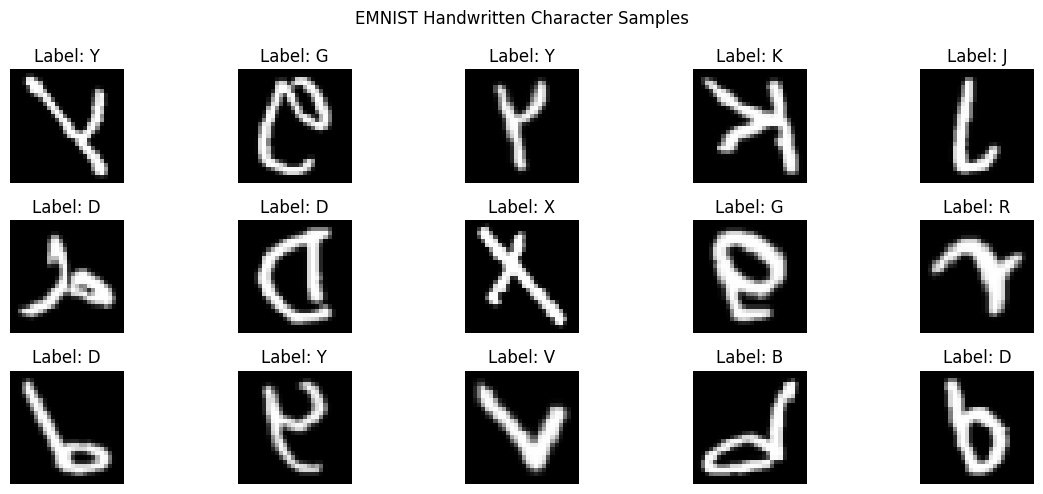

In [ ]:

plt.figure(figsize=(12, 5))

for i in range(15):
    plt.subplot(3, 5, i + 1)
    plt.imshow(X_train[i].squeeze(), cmap="gray")
    plt.title("Label: " + LETTERS[y_train[i]])
    plt.axis("off")

plt.suptitle("EMNIST Handwritten Character Samples")
plt.tight_layout()
plt.show()


In [ ]:

augmentation = tf.keras.Sequential([
    layers.RandomRotation(0.08, fill_mode="constant"),
    layers.RandomTranslation(0.08, 0.08, fill_mode="constant"),
    layers.RandomZoom(0.10, fill_mode="constant"),
    layers.RandomContrast(0.20),
    layers.GaussianNoise(0.08)
], name="robust_augmentation")

model = models.Sequential([
    layers.Input(shape=(28, 28, 1)),
    augmentation,

    layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.20),

    layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.35),
    layers.Dense(26, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ robust_augmentation             │ (None, 28, 28, 1)      │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 26, 26, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 13, 13, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 11, 11, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 26)             │         3,354 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 273,658 (1.04 MB)

 Trainable params: 273,466 (1.04 MB)

 Non-trainable params: 192 (768.00 B)

In [ ]:

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        patience=3,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "best_handwritten_cnn.keras",
        monitor="val_accuracy",
        save_best_only=True
    )
]

history = model.fit(
    X_train, y_train,
    validation_split=0.10,
    epochs=15,
    batch_size=128,
    callbacks=callbacks,
    verbose=1
)

print("Training completed!")


Epoch 1/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 279s 439ms/step - accuracy: 0.4829 - loss: 1.7046 - val_accuracy: 0.8494 - val_loss: 0.4724
Epoch 2/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 264s 422ms/step - accuracy: 0.7482 - loss: 0.8015 - val_accuracy: 0.9084 - val_loss: 0.2824
Epoch 3/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 269s 431ms/step - accuracy: 0.8099 - loss: 0.6030 - val_accuracy: 0.9195 - val_loss: 0.2487
Epoch 4/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 257s 411ms/step - accuracy: 0.8391 - loss: 0.5143 - val_accuracy: 0.9271 - val_loss: 0.2356
Epoch 5/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 264s 415ms/step - accuracy: 0.8560 - loss: 0.4571 - val_accuracy: 0.9248 - val_loss: 0.2328
Epoch 6/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 275s 436ms/step - accuracy: 0.8648 - loss: 0.4278 - val_accuracy: 0.9277 - val_loss: 0.2290
Epoch 7/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 262s 420ms/step - accuracy: 0.8726 - loss: 0.4013 - val_accuracy: 0.9267 - val_loss: 0.2243
Epoch 8/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 322s 420ms/step - accuracy: 0.8779 -

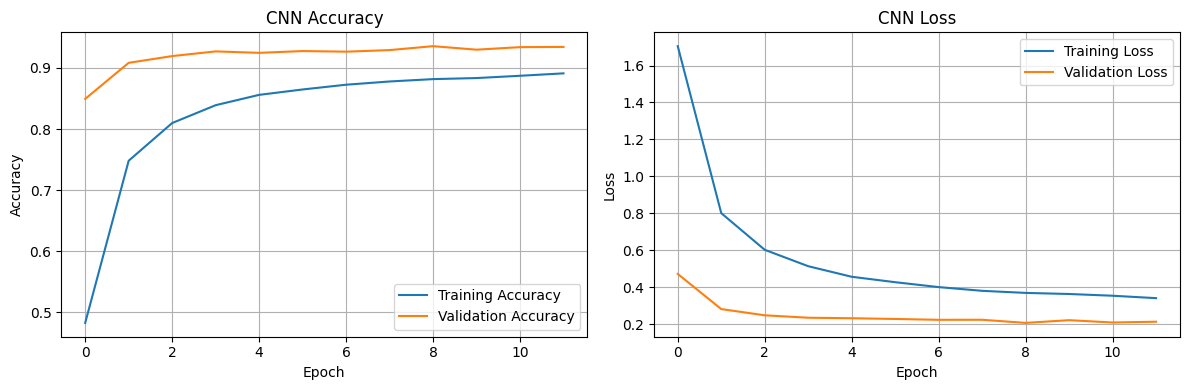

In [14]:

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


In [15]:

test_loss, test_accuracy = model.evaluate(
    X_test, y_test, batch_size=256, verbose=1
)

print(f"\nClean Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Clean Test Loss: {test_loss:.4f}")


58/58 ━━━━━━━━━━━━━━━━━━━━ 13s 229ms/step - accuracy: 0.9221 - loss: 0.2214

Clean Test Accuracy: 92.21%
Clean Test Loss: 0.2214


In [16]:

import cv2

# Use a fixed test subset for faster robustness testing
N = min(3000, len(X_test))
clean = X_test[:N].copy()
labels = y_test[:N]

def add_noise(images):
    noise = np.random.normal(0, 0.12, images.shape)
    return np.clip(images + noise, 0, 1).astype(np.float32)

def add_blur(images):
    result = []
    for img in images:
        blurred = cv2.GaussianBlur(img.squeeze(), (5, 5), 1.2)
        result.append(blurred[..., np.newaxis])
    return np.array(result, dtype=np.float32)

def add_rotation(images, angle=15):
    result = []
    for img in images:
        matrix = cv2.getRotationMatrix2D((13.5, 13.5), angle, 1.0)
        rotated = cv2.warpAffine(
            img.squeeze(), matrix, (28, 28),
            flags=cv2.INTER_LINEAR,
            borderMode=cv2.BORDER_CONSTANT,
            borderValue=0
        )
        result.append(rotated[..., np.newaxis])
    return np.array(result, dtype=np.float32)

def change_illumination(images):
    # Darker image with a small brightness offset
    return np.clip(images * 0.60 + 0.10, 0, 1).astype(np.float32)

test_conditions = {
    "Clean": clean,
    "Noise": add_noise(clean),
    "Blur": add_blur(clean),
    "Rotation": add_rotation(clean),
    "Illumination": change_illumination(clean)
}

results = {}

for condition, images in test_conditions.items():
    loss, accuracy = model.evaluate(
        images, labels, batch_size=256, verbose=0
    )
    results[condition] = accuracy * 100
    print(f"{condition:15s}: {accuracy * 100:.2f}% accuracy")

print("\nRobustness testing completed!")


Clean          : 91.87% accuracy
Noise          : 90.40% accuracy
Blur           : 89.27% accuracy
Rotation       : 91.17% accuracy
Illumination   : 65.10% accuracy

Robustness testing completed!


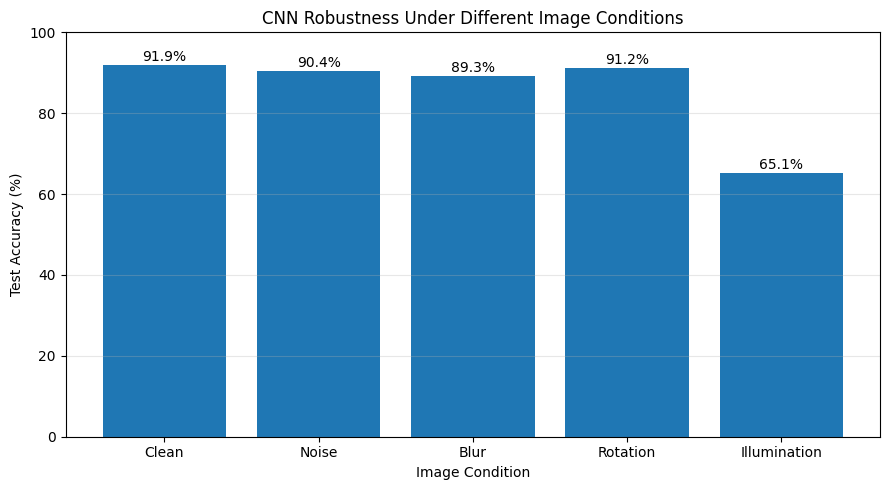

In [17]:

plt.figure(figsize=(9, 5))

bars = plt.bar(results.keys(), results.values())
plt.title("CNN Robustness Under Different Image Conditions")
plt.xlabel("Image Condition")
plt.ylabel("Test Accuracy (%)")
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)

for bar, value in zip(bars, results.values()):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value:.1f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()


58/58 ━━━━━━━━━━━━━━━━━━━━ 11s 181ms/step
              precision    recall  f1-score   support

           A       0.92      0.97      0.95       800
           B       0.97      0.98      0.98       800
           C       0.98      0.96      0.97       800
           D       0.96      0.96      0.96       800
           E       0.96      0.98      0.97       800
           F       0.99      0.94      0.96       800
           G       0.80      0.86      0.83       800
           H       0.96      0.95      0.95       800
           I       0.71      0.79      0.75       800
           J       0.98      0.94      0.96       800
           K       0.99      0.96      0.98       800
           L       0.77      0.68      0.73       800
           M       0.99      0.99      0.99       800
           N       0.96      0.96      0.96       800
           O       0.96      0.96      0.96       800
           P       0.97      0.99      0.98       800
           Q       0.88      0.76      

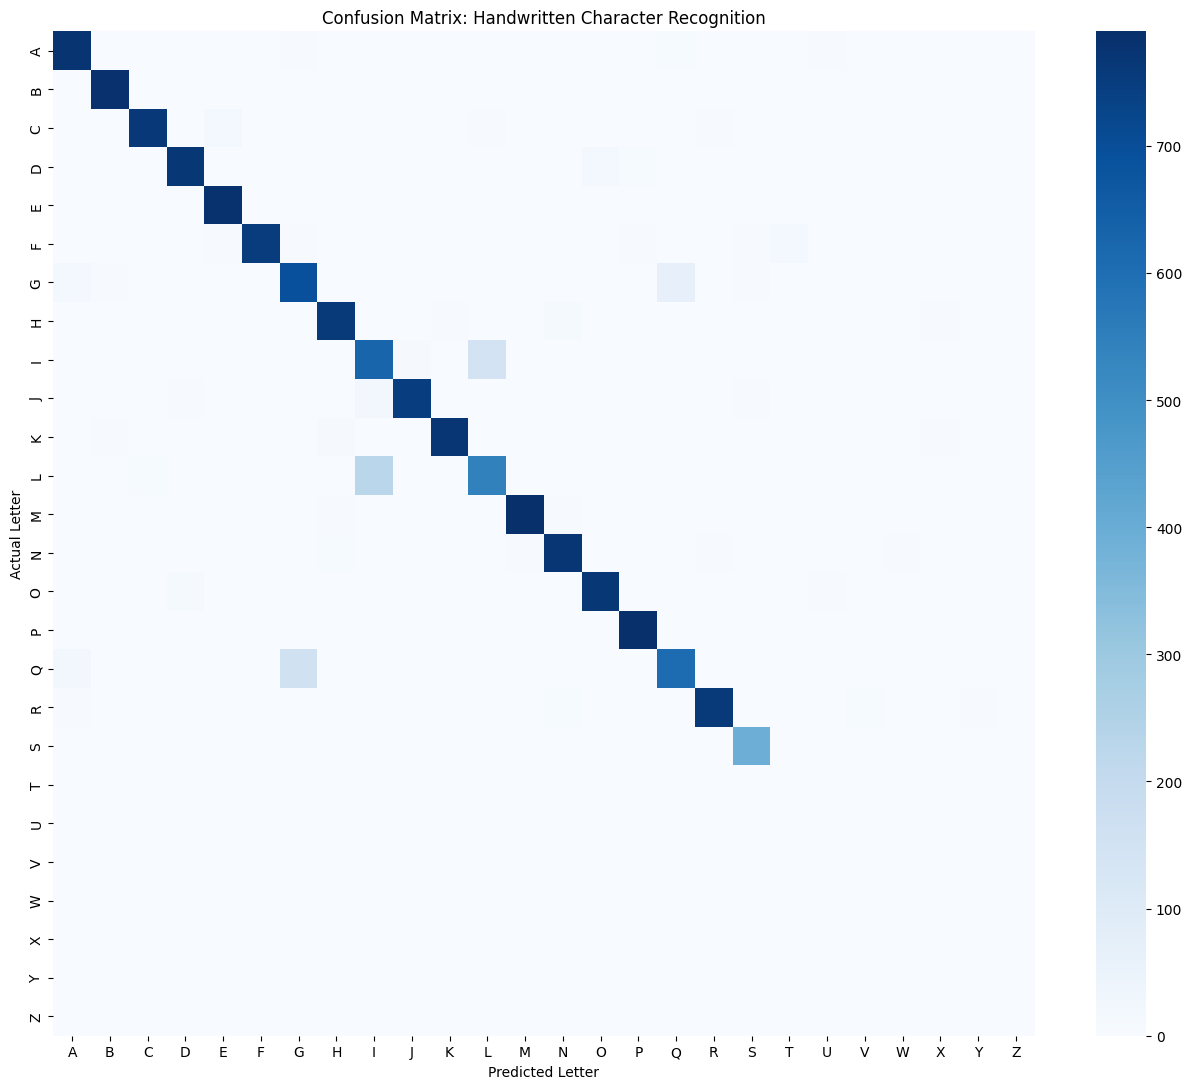

In [18]:

predictions = model.predict(X_test, batch_size=256, verbose=1)
y_pred = np.argmax(predictions, axis=1)

print(classification_report(
    y_test,
    y_pred,
    labels=np.arange(26),
    target_names=LETTERS,
    zero_division=0
))

cm = confusion_matrix(y_test, y_pred, labels=np.arange(26))

plt.figure(figsize=(13, 11))
sns.heatmap(
    cm,
    cmap="Blues",
    xticklabels=LETTERS,
    yticklabels=LETTERS
)
plt.title("Confusion Matrix: Handwritten Character Recognition")
plt.xlabel("Predicted Letter")
plt.ylabel("Actual Letter")
plt.tight_layout()
plt.show()


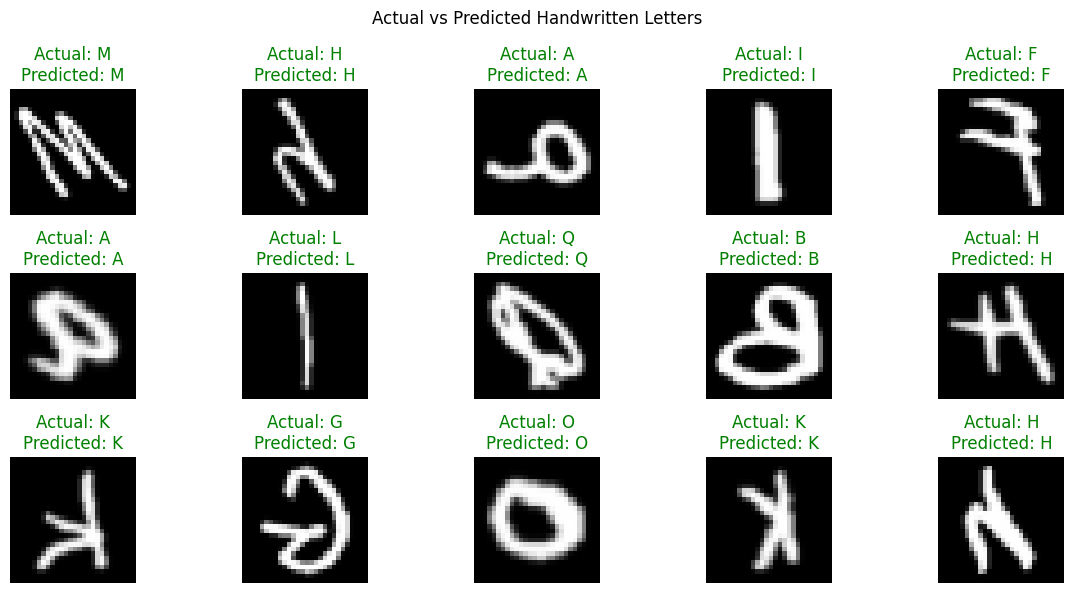

In [19]:

plt.figure(figsize=(12, 6))

for i in range(15):
    actual = y_test[i]
    predicted = y_pred[i]

    plt.subplot(3, 5, i + 1)
    plt.imshow(X_test[i].squeeze(), cmap="gray")

    color = "green" if actual == predicted else "red"
    plt.title(
        f"Actual: {LETTERS[actual]}\nPredicted: {LETTERS[predicted]}",
        color=color
    )
    plt.axis("off")

plt.suptitle("Actual vs Predicted Handwritten Letters")
plt.tight_layout()
plt.show()


Saving handwritten_C_capital.png to handwritten_C_capital.png


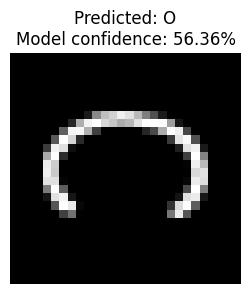

In [21]:

from google.colab import files
from PIL import Image, ImageOps
from IPython.display import display

uploaded = files.upload()

for filename in uploaded:
    image = Image.open(filename).convert("L")
    image = ImageOps.autocontrast(image)

    # Convert to a binary image and isolate the handwritten character
    gray = np.array(image)
    _, binary = cv2.threshold(
        gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
    )

    coords = cv2.findNonZero(binary)

    if coords is None:
        print("No character detected. Please upload another image.")
        continue

    x, y, w, h = cv2.boundingRect(coords)
    character = binary[y:y+h, x:x+w]

    # Preserve aspect ratio and center on a 28 x 28 canvas
    scale = 20.0 / max(w, h)
    new_w = max(1, int(w * scale))
    new_h = max(1, int(h * scale))

    resized = cv2.resize(
        character, (new_w, new_h),
        interpolation=cv2.INTER_AREA
    )

    canvas = np.zeros((28, 28), dtype=np.uint8)
    x_offset = (28 - new_w) // 2
    y_offset = (28 - new_h) // 2
    canvas[y_offset:y_offset+new_h,
           x_offset:x_offset+new_w] = resized

    # Convert to the dataset's orientation
    canvas = np.fliplr(canvas.T).copy()

    input_image = canvas.astype("float32")[None, ..., None] / 255.0
    probabilities = model.predict(input_image, verbose=0)[0]

    predicted_index = int(np.argmax(probabilities))
    confidence = float(probabilities[predicted_index]) * 100

    plt.figure(figsize=(3, 3))
    plt.imshow(canvas, cmap="gray")
    plt.title(
        f"Predicted: {LETTERS[predicted_index]}\n"
        f"Model confidence: {confidence:.2f}%"
    )
    plt.axis("off")
    plt.show()


In [22]:

model.save("robust_handwritten_cnn.keras")

print("Model saved successfully!")

from google.colab import files
files.download("robust_handwritten_cnn.keras")


Model saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>